In [1]:
from flowermd.library import LJChain, RandomWalk, PhantomWalk
import unyt as u
from flowermd.library.forcefields import DPD
import hoomd

molecules = LJChain(
    num_mols=[32],
    lengths=[1],
    bead_sequence=["_A"],
    bead_mass={"_A": 1.0},
    bond_lengths={"_A-_A": 1.0},
    identify_connections=False,
)

ref_length = 1.0 * u.Unit("nm")
ref_mass = 1.0 * u.Unit("g/mol")
ref_energy = 1.0 * u.Unit("kcal / mol")
ref_values_dict = {"length": ref_length, "mass": ref_mass, "energy": ref_energy}

system = RandomWalk(
    molecules=molecules,
    density=1.41 * u.Unit("nm**-3"),
    bond_length=1.0,
    base_units=ref_values_dict,
)

print(system.box)

A = 250000
gamma = 1500
kT = 1.0
r_cut = 1.01
bond_k = 250000
bond_r0 = 1.0
dpd_ff = DPD(
    A=A, gamma=gamma, kT=kT, r_cut=r_cut, bond_k=bond_k, bond_r0=bond_r0
)

sim = PhantomWalk(
    initial_state=system.hoomd_snapshot,
    forcefield=dpd_ff.hoomd_forces,
    gsd_write_freq=100,
    log_write_freq=50,
    n_steps_dpd=1000,
    n_steps_fire=200,
)

for writer in sim.operations.writers:
    if isinstance(writer, hoomd.write.GSD):
        writer.flush()

#sim_visualizer = FresnelGSD(
#    gsd_file="trajectory.gsd", frame=-1, view_axis=(1, 1, 1)
#)
#image = PIL.Image.fromarray(sim_visualizer.view()[:], mode="RGBA")
#image.save("output.png")

(32, 3)
Box: Lx=2.831242, Ly=2.831242, Lz=2.831242, xy=0.000000, xz=0.000000, yz=0.000000, 
Initializing simulation state from a gsd.hoomd.Frame.
Step 75 of 1000; TPS: 366.95; ETA: 0.0 minutes
Step 150 of 1000; TPS: 725.99; ETA: 0.0 minutes
Step 225 of 1000; TPS: 1083.57; ETA: 0.0 minutes
Step 300 of 1000; TPS: 1437.56; ETA: 0.0 minutes
Step 375 of 1000; TPS: 1791.24; ETA: 0.0 minutes
Step 450 of 1000; TPS: 2140.47; ETA: 0.0 minutes
Step 525 of 1000; TPS: 2489.43; ETA: 0.0 minutes
Step 600 of 1000; TPS: 2835.61; ETA: 0.0 minutes
Step 675 of 1000; TPS: 3181.16; ETA: 0.0 minutes
Step 750 of 1000; TPS: 3521.33; ETA: 0.0 minutes
Step 825 of 1000; TPS: 3861.4; ETA: 0.0 minutes
Step 900 of 1000; TPS: 4197.53; ETA: 0.0 minutes
Step 975 of 1000; TPS: 4532.92; ETA: 0.0 minutes
Step 50 of 200; TPS: 95057.03; ETA: 0.0 minutes
Step 125 of 200; TPS: 97809.08; ETA: 0.0 minutes
The closest particles after DPD + FIRE are:  0.918749988079071


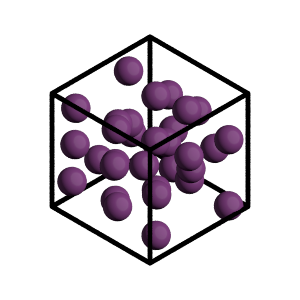

In [2]:
from cmeutils.visualize import FresnelGSD
import PIL

sim_visualizer = FresnelGSD(
    gsd_file="trajectory.gsd", frame=-1, view_axis=(1, 1, 1)
)
scene = sim_visualizer.view()
image = PIL.Image.fromarray(scene[:], mode="RGBA")
image.save("fcc.png")
scene